In [1]:
import sys, os, json, time, shutil
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "..")
sys.path.insert(0, "../datos")
import solucion
from evaluador import comparar, categoria_error, es_solo_lectura
from construir import ejecutar_sql, conectar

PESOS = {"facil": 1, "media": 2, "dificil": 3}
val = json.load(open("../datos/validacion_propia.json"))
esquemas = {b: open(f"../datos/esquemas_sql/{b}.sql").read() for b in {v["base"] for v in val}}
print(len(val), "preguntas")

40 preguntas


## 1. Usuario de solo lectura

La funcion `ejecutar` que recibe el modelo usa un usuario que solo puede hacer SELECT, igual que en la evaluacion del curso. Devuelve como maximo 10 filas.

In [2]:
cur = conectar().cursor()
cur.execute("CREATE USER IF NOT EXISTS 'lector'@'%' IDENTIFIED BY 'lector'")
for b in esquemas:
    cur.execute(f"GRANT SELECT ON {b}.* TO 'lector'@'%'")

import pymysql
def crear_ejecutar(base):
    def ejecutar(sql):
        con = pymysql.connect(host="127.0.0.1", user="lector", password="lector", database=base)
        try:
            c = con.cursor()
            c.execute(sql)
            return {"ok": True, "columnas": [d[0] for d in c.description], "filas": list(c.fetchmany(10)), "error": None}
        except Exception as e:
            return {"ok": False, "columnas": [], "filas": [], "error": str(e)}
        finally:
            con.close()
    return ejecutar

## 2. Funcion de evaluacion

In [3]:
def evaluar(nombre, usar_ejecutar=False, previo=None):
    filas = []
    inicio_total = time.time()
    for v in val:
        inicio = time.time()
        ejecutar = crear_ejecutar(v["base"]) if usar_ejecutar else None
        # La generacion es determinista: si ya tenemos la consulta de una corrida previa y corre sin error, es la misma que daria generar_sql
        if previo is not None and ejecutar(previo[v["pregunta"]])["ok"]:
            sql = previo[v["pregunta"]]
        else:
            sql = solucion.generar_sql(esquemas[v["base"]], v["pregunta"], ejecutar)
        segundos = time.time() - inicio
        ref = ejecutar_sql(v["base"], v["sql"])
        pred = ejecutar_sql(v["base"], sql) if es_solo_lectura(sql) else {"ok": False, "filas": [], "error": "no es SELECT"}
        acierto = pred["ok"] and comparar(ref["filas"], pred["filas"], v["ordenado"])
        filas.append({"corrida": nombre, "base": v["base"], "nivel": v["nivel"], "pregunta": v["pregunta"],
                      "sql_referencia": v["sql"], "sql_generado": sql, "acierto": acierto,
                      "categoria_error": "" if acierto else categoria_error(v["sql"], sql, pred["error"]),
                      "error_mysql": pred["error"] or "", "segundos": round(segundos, 1)})
    df = pd.DataFrame(filas)
    df["peso"] = df["nivel"].map(PESOS)
    ex = (df["peso"] * df["acierto"]).sum() / df["peso"].sum()
    print(f"{nombre}: EX {ex:.3f}, aciertos {df['acierto'].sum()} de {len(df)}, minutos {(time.time() - inicio_total) / 60:.1f}, segundos maximo por pregunta {df['segundos'].max()}")
    return df

## 3. Baseline sin adapter

In [4]:
solucion.cargar(usar_adapter=False)
res_base = evaluar("baseline")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

baseline: EX 0.620, aciertos 27 de 40, minutos 5.8, segundos maximo por pregunta 23.1


## 4. Configuraciones A y B

In [5]:
solucion.cargar(usar_adapter=True, adapter="../adapters/lora_r8")
res_a = evaluar("A_r8")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

A_r8: EX 0.544, aciertos 24 de 40, minutos 6.7, segundos maximo por pregunta 25.4


In [6]:
solucion.cargar(usar_adapter=True, adapter="../adapters/lora_r16")
res_b = evaluar("B_r16")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

B_r16: EX 0.570, aciertos 25 de 40, minutos 6.8, segundos maximo por pregunta 27.9


## 5. Elegimos la mejor configuracion

La mejor configuracion por EX se copia a la carpeta `adapter/`, que es la que usa `solucion.py`. Si hay empate nos quedamos con A porque tiene menos parametros.

In [7]:
def ex(df):
    return (df["peso"] * df["acierto"]).sum() / df["peso"].sum()

mejor = "lora_r8" if ex(res_a) >= ex(res_b) else "lora_r16"
print("Mejor configuracion:", mejor)
shutil.rmtree("../adapter", ignore_errors=True)
shutil.copytree(f"../adapters/{mejor}", "../adapter")
config_adapter = json.load(open("../adapter/adapter_config.json"))
config_adapter["base_model_name_or_path"] = solucion.CONFIG["modelo_base"]
json.dump(config_adapter, open("../adapter/adapter_config.json", "w"), indent=2)

Mejor configuracion: lora_r16


## 6. Experimento de inferencia: correccion con `ejecutar`

Hipotesis: cuando la consulta falla por un error de MySQL, por ejemplo una columna mal escrita, mostrarle el error al modelo le permite corregirla. Esperamos que ayude poco porque la mayoria de fallos no son errores de ejecucion sino resultados distintos.

In [8]:
solucion.cargar(usar_adapter=True, adapter="../adapter")
res_mejor = res_a if mejor == "lora_r8" else res_b
res_corr = evaluar("mejor_con_ejecutar", usar_ejecutar=True, previo=dict(zip(res_mejor["pregunta"], res_mejor["sql_generado"])))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

mejor_con_ejecutar: EX 0.570, aciertos 25 de 40, minutos 1.9, segundos maximo por pregunta 78.3


## 7. Resultados

In [9]:
todos = pd.concat([res_base, res_a, res_b, res_corr])
os.makedirs("../resultados", exist_ok=True)
todos.to_csv("../resultados/validacion_propia.csv", index=False)

tabla = []
for nombre, df in todos.groupby("corrida", sort=False):
    fila = {"corrida": nombre, "EX": round(ex(df), 3), "aciertos": int(df["acierto"].sum())}
    for nivel in PESOS:
        d = df[df["nivel"] == nivel]
        fila[nivel] = f"{int(d['acierto'].sum())} de {len(d)}"
    fila["segundos_promedio"] = round(df["segundos"].mean(), 1)
    tabla.append(fila)
tabla = pd.DataFrame(tabla)
tabla.to_csv("../resultados/resumen_ex.csv", index=False)
tabla

,corrida,EX,aciertos,facil,media,dificil,segundos_promedio
0,baseline,0.620,27,11 de 13,10 de 15,6 de 12,8.5
1,A_r8,0.544,24,11 de 13,7 de 15,6 de 12,10.0
2,B_r16,0.570,25,11 de 13,8 de 15,6 de 12,10.1
3,mejor_con_ejecutar,0.570,25,11 de 13,8 de 15,6 de 12,2.7


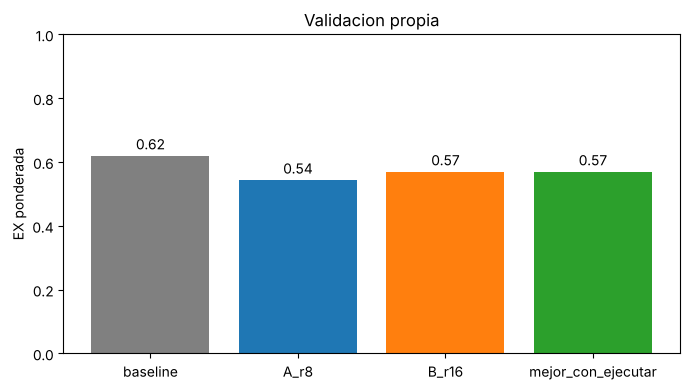

In [10]:
plt.figure(figsize=(7, 4))
plt.bar(tabla["corrida"], tabla["EX"], color=["gray", "tab:blue", "tab:orange", "tab:green"])
plt.ylabel("EX ponderada")
plt.title("Validacion propia")
plt.ylim(0, 1)
for i, v in enumerate(tabla["EX"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.savefig("../resultados/ex_por_corrida.png", dpi=120)
plt.show()

## 8. Analisis de errores por categoria

Las categorias son sintaxis, columna o tabla inexistente, JOIN, agregacion, filtro y resultado distinto. La categoria se asigna con reglas simples: primero se mira el codigo de error de MySQL y si la consulta corre se compara que partes tiene la consulta generada contra la de referencia.

In [11]:
errores = todos[~todos["acierto"]]
conteo = pd.crosstab(errores["categoria_error"], errores["corrida"]).reindex(columns=tabla["corrida"], fill_value=0)
conteo.to_csv("../resultados/errores_por_categoria.csv")
conteo

corrida,baseline,A_r8,B_r16,mejor_con_ejecutar
categoria_error,,,,
JOIN,2,3,5,5
agregacion,2,1,2,2
columna o tabla inexistente,1,4,1,0
filtro,0,1,0,0
resultado distinto,7,7,7,8
sintaxis,1,0,0,0


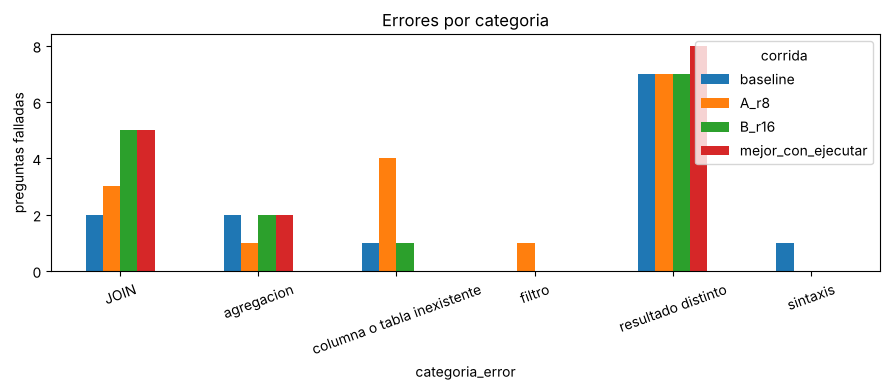

In [12]:
conteo.plot(kind="bar", figsize=(9, 4))
plt.ylabel("preguntas falladas")
plt.title("Errores por categoria")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../resultados/errores_por_categoria.png", dpi=120)
plt.show()

Algunos ejemplos de errores de la mejor configuracion:

In [13]:
for _, f in res_corr[~res_corr["acierto"]].head(8).iterrows():
    print(f["nivel"], "|", f["categoria_error"], "|", f["pregunta"])
    print("  referencia:", f["sql_referencia"])
    print("  generado:  ", f["sql_generado"])

facil | resultado distinto | ¿Qué especialidades distintas tienen los veterinarios? Devuelve la especialidad.
  referencia: SELECT DISTINCT vet_esp FROM vet_vets;
  generado:   SELECT vet_esp FROM vet_vets;
media | resultado distinto | Calcula el total gastado en consultas por cada especie de mascota. Devuelve especie y total.
  referencia: SELECT m.masc_esp, SUM(c.cons_costo) AS total FROM vet_cons c JOIN vet_masc m ON c.masc_id = m.masc_id GROUP BY m.masc_esp;
  generado:   SELECT h.masc_esp, SUM(p.cons_costo) AS total FROM vet_cons p JOIN vet_masc h ON h.masc_id = p.masc_id GROUP BY h.masc_id, h.masc_esp;
media | JOIN | Muestra el nombre de las mascotas atendidas por veterinarios de dermatologia, sin repetir.
  referencia: SELECT DISTINCT m.masc_nom FROM vet_cons c JOIN vet_masc m ON c.masc_id = m.masc_id JOIN vet_vets v ON c.vet_id = v.vet_id WHERE v.vet_esp = 'dermatologia';
  generado:   SELECT masc_nom FROM vet_masc WHERE due_id IN (SELECT due_id FROM vet_vets WHERE vet_esp = 'd

## 9. Revisiones del contrato

Revisamos que todas las consultas generadas sean SELECT o WITH y que la generacion sea determinista corriendo dos veces la misma pregunta.

In [14]:
print("Todas son SELECT o WITH:", todos["sql_generado"].apply(es_solo_lectura).all())
v = val[20]
s1 = solucion.generar_sql(esquemas[v["base"]], v["pregunta"])
s2 = solucion.generar_sql(esquemas[v["base"]], v["pregunta"])
print("Misma salida en dos corridas:", s1 == s2)
print(s1)

Todas son SELECT o WITH: True


Misma salida en dos corridas: True
SELECT h.due_nom, SUM(p.cons_costo) AS gasto FROM vet_duenos h JOIN vet_cons p ON p.masc_id = h.due_id GROUP BY h.due_id, h.due_nom HAVING SUM(p.cons_costo) > (SELECT AVG(gasto) FROM (SELECT SUM(p.cons_costo) AS gasto FROM vet_duenos h JOIN vet_cons p ON p.masc_id = h.due_id GROUP BY h.due_id, h.due_nom) AS gasto);
